# Dataset integrity before a prompting comparison

I want to know what the data can support before interpreting a model comparison. The earlier pipeline had conversation leakage, and the archived dataset lacked row-level provenance. This notebook records an agent-assisted audit, not a personal claim that I independently collected the data. No archived dialogue is displayed or used for prompting.

The practical choice is to quarantine the historical artifact and run a small synthetic pilot. Keeping it merely because it resembles EmpatheticDialogues would confuse similarity with permission and correct pairing. [EmpatheticDialogues](https://github.com/facebookresearch/EmpatheticDialogues/blob/main/LICENSE) and [ESConv](https://github.com/thu-coai/Emotional-Support-Conversation/blob/main/LICENSE) both carry CC BY-NC 4.0 terms; ESConv additionally states academic-only use. These sources remain relevant alternatives, but the pilot does not redistribute their conversations.

In [1]:
from pathlib import Path
import json, subprocess, sys
ROOT = Path.cwd() if (Path.cwd()/'scripts').exists() else Path.cwd().parent
assert (ROOT/'scripts/audit_dataset_integrity.py').exists()
result = subprocess.run([sys.executable, 'scripts/audit_dataset_integrity.py'], cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
assert result.returncode == 0, result.stderr
audit = json.loads((ROOT/'results/milestone_3/dataset_integrity.json').read_text())
audit['quarantine']

{'path': 'archive/quarantine/empathy_42k.jsonl.quarantined', 'sha256': 'a78dac24c48e4b14282de4f7293f54f5984a06dc56f717dd4b317dda7cab6891', 'rows': 15000, 'duplicate_pair_rows': 26, 'duplicate_prompt_rows': 4337, 'rows_with_escaped_comma': 5759}

## How the provenance check works

The audit normalises case, whitespace and the dataset’s escaped comma marker. It counts repeated prompt–response pairs separately from repeated prompts. Matching a prompt to an official situation and a response to an utterance does not establish that they belong together. The comparison also cannot reconstruct consent or an acquisition licence from text alone. Only counts and hashes are exported.

In [2]:
audit['source_similarity_not_provenance']

{'data/raw/empatheticdialogues/test.csv': {'archive_prompt_rows_matching_situation': 2, 'archive_response_rows_matching_utterance': 135, 'sha256': 'a014199d689a11bfd58c19a406ccf18c4fdffd1eb45c5eb31a3a1c880dc15958'}, 'data/raw/empatheticdialogues/train.csv': {'archive_prompt_rows_matching_situation': 15000, 'archive_response_rows_matching_utterance': 15000, 'sha256': '35053a4e1ef39f6766e7706c9a3c97b8fa090cfb28d32087a8316a606ab1a7dd'}, 'data/raw/empatheticdialogues/valid.csv': {'archive_prompt_rows_matching_situation': 6, 'archive_response_rows_matching_utterance': 126, 'sha256': 'd8a1f0b1281cf60a803b88d5c500f10112461a8fbc87be13dfb5eb5277e664b3'}}

## Conversation-level separation

A held-out row can still contain familiar context when a neighbouring turn appears in a development prompt. For that reason, the checker compares conversation IDs across all six partitions. Exact normalised pair checks provide a second, narrower view. Neither check rules out paraphrases, topic overlap or information learned during pretraining.

In [3]:
check = subprocess.run([sys.executable, 'scripts/check_leakage.py', '--out', 'results/milestone_3/leakage.json'], cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
assert check.returncode == 0, check.stderr
leakage = json.loads((ROOT/'results/milestone_3/leakage.json').read_text())
{'counts': leakage['counts'], 'group_intersections': leakage['overlap'], 'pair_intersections': audit['active_normalised_pair_intersections'], 'fewshot_input_intersections': audit['fewshot_input_intersections']}

{'counts': {'train': 25721, 'dev': 2873, 'fewshot': 4, 'val': 4534, 'test_seen': 4181, 'test_unseen': 839}, 'group_intersections': {'train__dev': 0, 'train__fewshot': 0, 'train__val': 0, 'train__test_seen': 0, 'train__test_unseen': 0, 'dev__fewshot': 0, 'dev__val': 0, 'dev__test_seen': 0, 'dev__test_unseen': 0, 'fewshot__val': 0, 'fewshot__test_seen': 0, 'fewshot__test_unseen': 0, 'val__test_seen': 0, 'val__test_unseen': 0, 'test_seen__test_unseen': 0}, 'pair_intersections': {'train__dev': 0, 'train__fewshot': 0, 'train__val': 0, 'train__test_seen': 0, 'train__test_unseen': 0, 'dev__fewshot': 0, 'dev__val': 0, 'dev__test_seen': 0, 'dev__test_unseen': 0, 'fewshot__val': 0, 'fewshot__test_seen': 0, 'fewshot__test_unseen': 0, 'val__test_seen': 0, 'val__test_unseen': 0, 'test_seen__test_unseen': 0}, 'fewshot_input_intersections': {'val': 0, 'test_seen': 0, 'test_unseen': 0}}

## Interpreting the recorded evidence

The archive contains 15,000 rows, with 26 repeated normalised pairs and 4,337 repeated prompts. Every prompt and response individually matches the local training source, but this does not rehabilitate its unreliable pairing or undocumented provenance. The quarantine is therefore retained. The active split checks show no cross-partition conversation or exact-pair overlap, while preserving the frozen test hashes.

The synthetic pilot has a different purpose: it provides inspectable development and test scenarios without real participants. Agent review can check coherence and obvious identifiers, but it cannot replace independent safety review. The dataset card records this distinction. No training or public redistribution is approved by these findings.

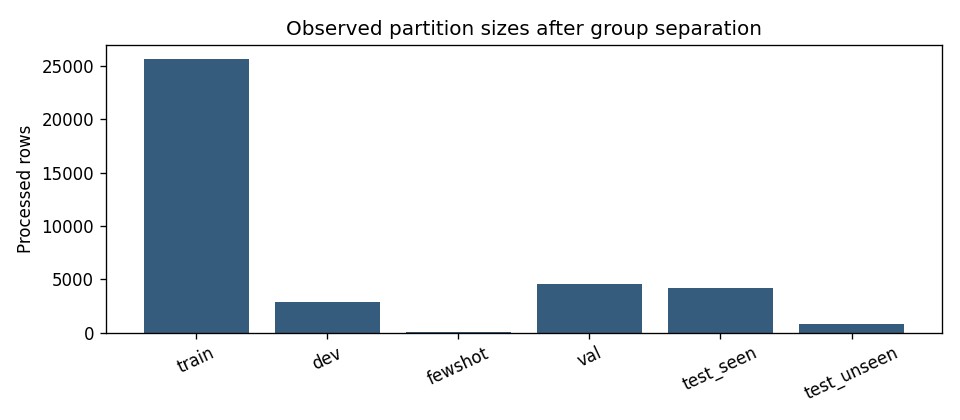

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8,3.5))
ax.bar(list(leakage['counts']), list(leakage['counts'].values()), color='#355c7d')
ax.set_ylabel('Processed rows'); ax.set_title('Observed partition sizes after group separation')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(ROOT/'results/milestone_3/dataset_partition_counts.png', dpi=150)
plt.show()

## Problems, limits and next decision

The original instructions misidentified the dataset licence, and the old file lacks source IDs. Those failures cannot be repaired by renaming it or deleting duplicate rows. The current raw files were hashed but not independently re-downloaded in this audit. No semantic deduplication or pretraining-contamination test has been completed.

The result supports proceeding with the explicitly synthetic, group-separated local pilot under the accepted browser exception. It does not clear the archive for reuse, validate the application’s medical copy or establish readiness for LoRA. The next evidence is the frozen A/B experiment, followed by independent ratings and a larger reviewed benchmark.